# COU 07506 Digital Signal Processing
## Week 2 — Lab 1A: Sampling, Aliasing and Quantization

**Name:** Deborah  
**Registration Number:** 240242455798  
**Class:** BEng24COE  
**Laboratory:** Week 2  
**Academic Year:** 2026/2027

---

## Pre-lab Preparation

### Question (a)
A 7 kHz tone is sampled at 10 kHz. What frequency appears?

The Nyquist frequency is:

\[
f_N=\frac{f_s}{2}=\frac{10}{2}=5\text{ kHz}
\]

Since 7 kHz is above the Nyquist frequency, aliasing occurs.

\[
f_{\text{alias}}=|7-10|=3\text{ kHz}
\]

**Answer:** The apparent frequency is 3 kHz.

### Question (b)
Compute the quantization step size and theoretical SQNR for an 8-bit quantizer with a ±1 V range.

Given:

- Number of bits: \(B=8\)
- Full-scale range: \(-1\text{ V}\) to \(+1\text{ V}\)
- \(X_m=1\text{ V}\)

Quantization step size:

\[
\Delta=\frac{2X_m}{2^B}
=\frac{2}{256}
=0.0078125\text{ V}
\]

Theoretical SQNR:

\[
SQNR=6.02B+1.76
\]

\[
SQNR=6.02(8)+1.76=49.92\text{ dB}
\]

**Answer:**
- Quantization step size = 0.0078125 V
- Theoretical SQNR = 49.92 dB

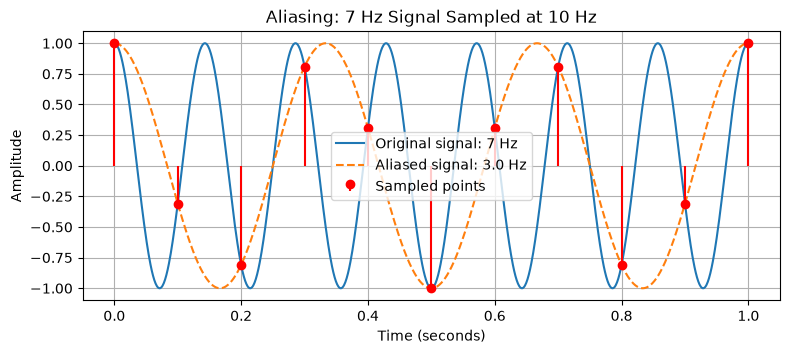

Original frequency: 7 Hz
Sampling frequency: 10 Hz
Nyquist frequency: 5.0 Hz
Alias frequency: 3.0 Hz


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Original signal parameters
f0 = 7          # Original frequency in Hz
fs = 10         # Sampling frequency in Hz
duration = 1    # Duration in seconds

# Dense time vector for plotting the continuous-looking signal
t = np.linspace(0, duration, 1000)

# Original 7 Hz cosine
x = np.cos(2 * np.pi * f0 * t)

# Sampling instants
n = np.arange(0, int(fs * duration) + 1)
t_samples = n / fs
x_samples = np.cos(2 * np.pi * f0 * t_samples)

# Calculate the alias frequency
f_alias = abs(((f0 + fs / 2) % fs) - fs / 2)

# Aliased signal
x_alias = np.cos(2 * np.pi * f_alias * t)

# Plot
plt.figure()
plt.plot(t, x, label="Original signal: 7 Hz")
plt.plot(t, x_alias, "--", label=f"Aliased signal: {f_alias} Hz")
plt.stem(t_samples, x_samples, linefmt="r-", markerfmt="ro",
         basefmt=" ", label="Sampled points")

plt.title("Aliasing: 7 Hz Signal Sampled at 10 Hz")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

print("Original frequency:", f0, "Hz")
print("Sampling frequency:", fs, "Hz")
print("Nyquist frequency:", fs / 2, "Hz")
print("Alias frequency:", f_alias, "Hz")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

f0 = 7
sampling_frequencies = [10, 12, 14, 20]

print("Original signal frequency:", f0, "Hz")
print("\nSampling Frequency | Nyquist Frequency | Alias Frequency")
print("---------------------------------------------------------")

for fs in sampling_frequencies:
    f_alias = abs(((f0 + fs / 2) % fs) - fs / 2)

    print(
        f"{fs:18} | {fs / 2:18} | {f_alias:15} Hz"
    )

Original signal frequency: 7 Hz

Sampling Frequency | Nyquist Frequency | Alias Frequency
---------------------------------------------------------
                10 |                5.0 |             3.0 Hz
                12 |                6.0 |             5.0 Hz
                14 |                7.0 |             7.0 Hz
                20 |               10.0 |             7.0 Hz


### Task 2.1 — Observations

The 7 Hz signal sampled at 10 Hz produces an alias frequency of 3 Hz because the original frequency exceeds the Nyquist frequency of 5 Hz.

When the sampling frequency is increased to 12 Hz, the alias frequency becomes 5 Hz. At 14 Hz, the sampling frequency is exactly twice the original signal frequency, placing the signal at the Nyquist frequency. At 20 Hz, the sampling frequency is sufficiently high to represent the original 7 Hz signal without aliasing.

These results demonstrate that the sampling frequency determines whether a signal can be accurately represented in discrete time. According to the Nyquist sampling theorem, the sampling frequency must be greater than twice the highest frequency component of the signal for reliable reconstruction.

## Task 2.2 — Downsampling and Anti-Aliasing

### Objective

To investigate the effects of downsampling a signal without filtering and compare the results with downsampling after applying an anti-aliasing filter.

### Procedure

A 3-second chirp signal with a sampling frequency of 44.1 kHz will be generated. Its frequency increases linearly from 200 Hz to 15 kHz.

The signal will then be downsampled by factors of 2, 4, and 8 using both naïve downsampling and filtered downsampling.

Original sampling frequency: 44100 Hz
Signal duration: 3 seconds
Number of samples: 132300
Starting frequency: 200 Hz
Ending frequency: 15000 Hz


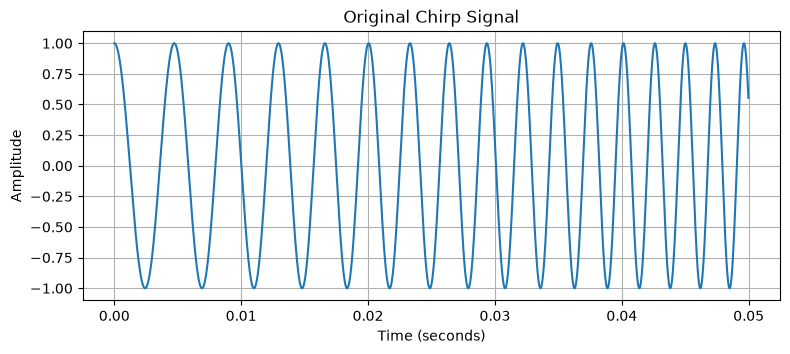

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# Generate a 3-second chirp signal
fs = 44100
duration = 3

t = np.arange(0, duration, 1/fs)

x = signal.chirp(
    t,
    f0=200,
    f1=15000,
    t1=duration,
    method="linear"
)

print("Original sampling frequency:", fs, "Hz")
print("Signal duration:", duration, "seconds")
print("Number of samples:", len(x))
print("Starting frequency: 200 Hz")
print("Ending frequency: 15000 Hz")

# Plot the first 0.05 seconds
plt.figure()
plt.plot(t[:2205], x[:2205])
plt.title("Original Chirp Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

Original sampling frequency: 44100 Hz
Signal duration: 3 seconds
Number of samples: 132300
Starting frequency: 200 Hz
Ending frequency: 15000 Hz


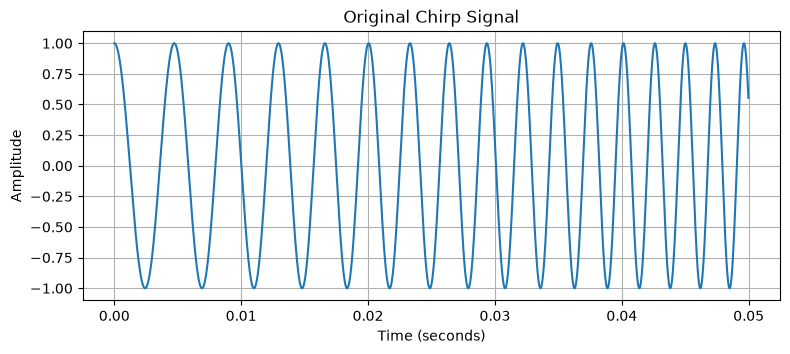

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# Generate a 3-second chirp signal
fs = 44100
duration = 3

t = np.arange(0, duration, 1/fs)

x = signal.chirp(
    t,
    f0=200,
    f1=15000,
    t1=duration,
    method="linear"
)

print("Original sampling frequency:", fs, "Hz")
print("Signal duration:", duration, "seconds")
print("Number of samples:", len(x))
print("Starting frequency: 200 Hz")
print("Ending frequency: 15000 Hz")

# Plot the first 0.05 seconds
plt.figure()
plt.plot(t[:2205], x[:2205])
plt.title("Original Chirp Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


Downsampling factor: 2
New sampling frequency: 22050.0 Hz
Naive samples: 66150
Filtered samples: 66150


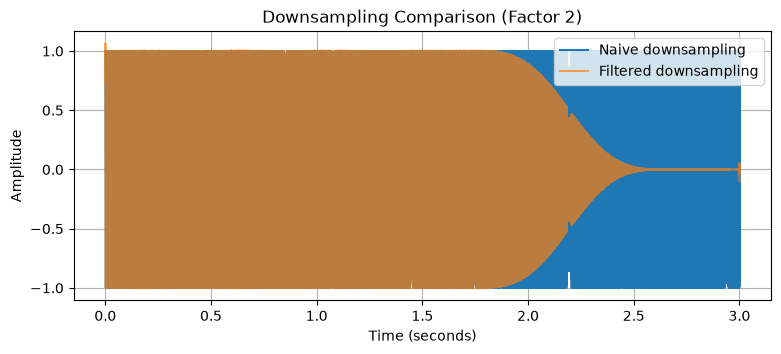


Downsampling factor: 4
New sampling frequency: 11025.0 Hz
Naive samples: 33075
Filtered samples: 33075


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# Downsampling factors
factors = [2, 4, 8]

for k in factors:

    # Naive downsampling: keep every kth sample
    x_naive = x[::k]

    # Filtered downsampling
    x_filtered = signal.decimate(x, k, ftype="fir")

    # New sampling frequency
    new_fs = fs / k

    print(f"\nDownsampling factor: {k}")
    print("New sampling frequency:", new_fs, "Hz")
    print("Naive samples:", len(x_naive))
    print("Filtered samples:", len(x_filtered))

    # Plot comparison
    t_naive = np.arange(len(x_naive)) / new_fs
    t_filtered = np.arange(len(x_filtered)) / new_fs

    plt.figure()
    plt.plot(t_naive, x_naive, label="Naive downsampling")
    plt.plot(t_filtered, x_filtered, label="Filtered downsampling",
             alpha=0.7)

    plt.title(f"Downsampling Comparison (Factor {k})")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# Downsampling factor
k = 8

# Naive downsampling
x_naive = x[::k]

# Filtered downsampling
x_filtered = signal.decimate(x, k, ftype="fir")

# New sampling frequency
new_fs = fs // k

print("New sampling frequency:", new_fs, "Hz")

print("\nNaive downsampling:")
display(Audio(x_naive, rate=new_fs))

print("\nFiltered downsampling:")
display(Audio(x_filtered, rate=new_fs))

## Task 2.3 — Uniform Quantization

### Objective

To investigate the effect of quantization on a discrete-time signal by representing its amplitude using a limited number of bits.

### Procedure

A 300 Hz sinusoidal signal will be generated with a sampling frequency of 8 kHz. The signal will be quantized using a 3-bit uniform quantizer.

The original signal, quantized signal, and quantization error will be plotted for comparison.

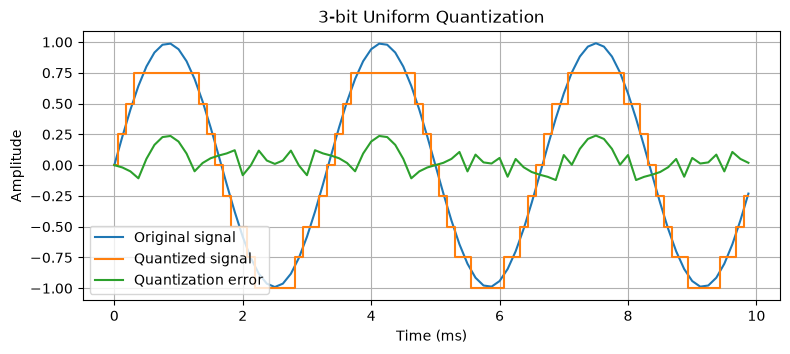

Sampling frequency: 8000 Hz
Quantization bits: 3
Quantization levels: 8
Quantization step size: 0.25 V


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Define the quantization function
def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / (2 ** bits)
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Generate a 300 Hz sinusoidal signal
fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# Apply 3-bit quantization
xq = quantize(x, 3)

# Calculate quantization error
error = x - xq

# Plot original and quantized signals
plt.figure()
plt.plot(t * 1000, x, label="Original signal")
plt.step(t * 1000, xq, where="mid", label="Quantized signal")
plt.plot(t * 1000, error, label="Quantization error")

plt.title("3-bit Uniform Quantization")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

# Display quantization information
print("Sampling frequency:", fs, "Hz")
print("Quantization bits: 3")
print("Quantization levels:", 2 ** 3)
print("Quantization step size:", 2 / (2 ** 3), "V")

## Task 2.4 — Signal-to-Quantization-Noise Ratio (SQNR)

### Objective

To investigate how the number of quantization bits affects the Signal-to-Quantization-Noise Ratio (SQNR).

### Procedure

The sinusoidal signal generated in Task 2.3 will be quantized using bit depths ranging from 2 to 16 bits in steps of 2.

The measured SQNR will be calculated and compared with the theoretical SQNR using the relationship:

\[
SQNR = 6.02B + 1.76 \text{ dB}
\]

where \(B\) represents the number of quantization bits.

Bits | Measured SQNR (dB) | Theoretical SQNR (dB)
------------------------------------------------
   2 |                9.60 |                 13.80
   4 |               23.58 |                 25.84
   6 |               36.81 |                 37.88
   8 |               48.93 |                 49.92
  10 |               62.81 |                 61.96
  12 |               72.84 |                 74.00
  14 |               88.13 |                 86.04
  16 |               98.91 |                 98.08


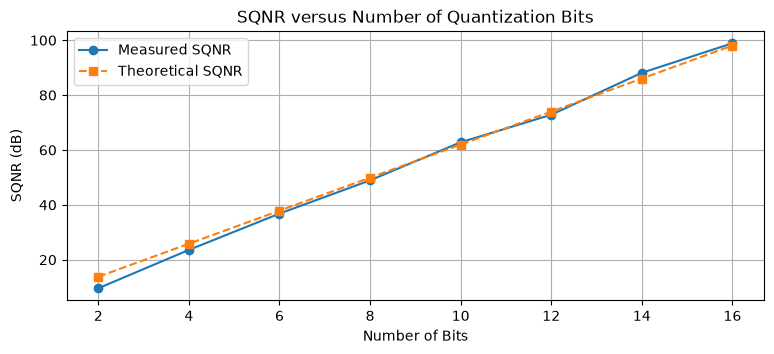

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

# Use the sinusoidal signal from Task 2.3
bits_range = np.arange(2, 17, 2)

measured_sqnr = []
theoretical_sqnr = []

for bits in bits_range:

    # Quantize the signal
    xq = quantize(x, bits)

    # Calculate quantization noise
    error = x - xq

    # Calculate measured SQNR
    sqnr = 10 * np.log10(
        np.sum(x ** 2) / np.sum(error ** 2)
    )

    measured_sqnr.append(sqnr)

    # Calculate theoretical SQNR
    theoretical = 6.02 * bits + 1.76
    theoretical_sqnr.append(theoretical)

# Display results
print("Bits | Measured SQNR (dB) | Theoretical SQNR (dB)")
print("------------------------------------------------")

for bits, measured, theoretical in zip(
    bits_range, measured_sqnr, theoretical_sqnr
):
    print(f"{bits:4} | {measured:19.2f} | {theoretical:21.2f}")

# Plot results
plt.figure()
plt.plot(bits_range, measured_sqnr, "o-", label="Measured SQNR")
plt.plot(bits_range, theoretical_sqnr, "s--", label="Theoretical SQNR")

plt.title("SQNR versus Number of Quantization Bits")
plt.xlabel("Number of Bits")
plt.ylabel("SQNR (dB)")
plt.xticks(bits_range)
plt.legend()
plt.grid(True)
plt.show()

### Task 2.4 — Observations

The results show that the Signal-to-Quantization-Noise Ratio (SQNR) generally increases as the number of quantization bits increases.

Increasing the number of bits increases the number of available quantization levels and reduces the quantization step size. Consequently, the quantization error becomes smaller and the signal quality improves.

The theoretical SQNR increases by approximately 6.02 dB for every additional bit. The measured SQNR may differ slightly from the theoretical value because the theoretical formula assumes an ideal full-scale sinusoidal signal and ideal quantization conditions.

Therefore, using more quantization bits improves the accuracy of digital signal representation.

## Task 2.5 — Quantization of an Audio Signal

### Objective

To investigate how different quantization bit depths affect the quality of an audio signal.

### Procedure

An audio signal will be quantized using 4-bit, 8-bit, and 12-bit quantizers. The resulting signals will be compared by listening to them and calculating their Signal-to-Quantization-Noise Ratios (SQNR).

Sampling frequency: 16000 Hz
Number of samples: 32000
Duration: 2.0 seconds
Signal type: Synthetic 440 Hz decaying tone


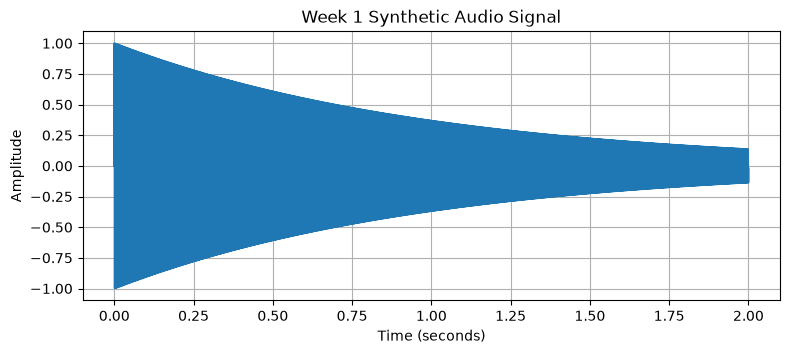

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# Load the Week 1 synthetic audio file
fs_audio, audio = wavfile.read("test_audio.wav")

# Convert audio to floating-point values
audio = audio.astype(np.float64)

# Normalize if the audio uses integer PCM values
if np.max(np.abs(audio)) > 1:
    audio = audio / np.max(np.abs(audio))

# Display audio information
print("Sampling frequency:", fs_audio, "Hz")
print("Number of samples:", len(audio))
print("Duration:", len(audio) / fs_audio, "seconds")
print("Signal type: Synthetic 440 Hz decaying tone")

# Plot the audio signal
t_audio = np.arange(len(audio)) / fs_audio

plt.figure()
plt.plot(t_audio, audio)
plt.title("Week 1 Synthetic Audio Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

# Listen to the original signal
display(Audio(audio, rate=fs_audio))

4-bit quantization:
SQNR: 19.74 dB

8-bit quantization:
SQNR: 43.82 dB

12-bit quantization:
SQNR: 67.93 dB



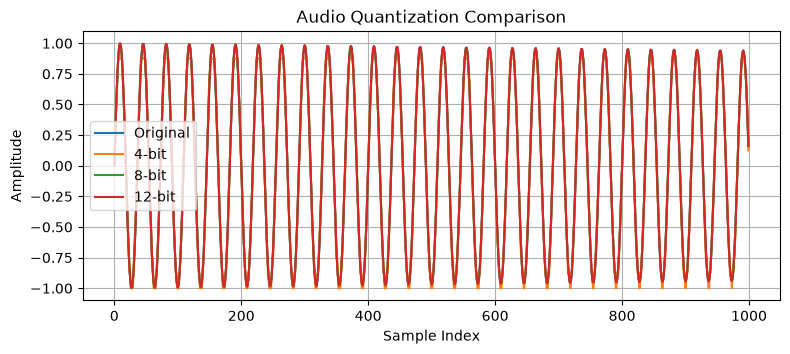

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

# Quantization bit depths
bit_depths = [4, 8, 12]

# Store quantized signals and SQNR values
quantized_audio = {}
audio_sqnr = {}

# Quantize and calculate SQNR
for bits in bit_depths:

    audio_q = quantize(audio, bits)

    error = audio - audio_q

    sqnr = 10 * np.log10(
        np.sum(audio ** 2) / np.sum(error ** 2)
    )

    quantized_audio[bits] = audio_q
    audio_sqnr[bits] = sqnr

    print(f"{bits}-bit quantization:")
    print(f"SQNR: {sqnr:.2f} dB")
    print()

# Plot comparison
plt.figure()

plt.plot(audio[:1000], label="Original")

for bits in bit_depths:
    plt.plot(
        quantized_audio[bits][:1000],
        label=f"{bits}-bit"
    )

plt.title("Audio Quantization Comparison")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Original audio:")
display(Audio(audio, rate=fs_audio))

print("4-bit quantized audio:")
display(Audio(quantized_audio[4], rate=fs_audio))

print("8-bit quantized audio:")
display(Audio(quantized_audio[8], rate=fs_audio))

print("12-bit quantized audio:")
display(Audio(quantized_audio[12], rate=fs_audio))

Original audio:


4-bit quantized audio:


8-bit quantized audio:


12-bit quantized audio:


### Task 2.5 — Audio Quantization Observations

The synthetic audio signal from Week 1 was quantized using 4-bit, 8-bit, and 12-bit quantizers.

The 4-bit quantized signal has fewer amplitude levels, resulting in a larger quantization error and lower SQNR. The 8-bit signal provides better amplitude resolution and improved signal quality. The 12-bit signal provides the highest resolution among the three and produces the smallest quantization error.

The results demonstrate that increasing the number of quantization bits improves audio signal representation by reducing quantization noise.

**Note:** The experiment used a synthetic 440 Hz decaying tone rather than a human voice recording.

## Analysis Questions

### Question 1: Explain with a frequency-axis sketch why a 7 Hz tone appears at 3 Hz when sampled at 10 Hz.

The sampling frequency is 10 Hz, therefore the Nyquist frequency is:

\[
f_N=\frac{f_s}{2}=\frac{10}{2}=5\text{ Hz}
\]

The original 7 Hz signal exceeds the Nyquist frequency. During sampling, it becomes indistinguishable from a 3 Hz signal because:

\[
f_{\text{alias}}=|f_s-f_0|
\]

\[
f_{\text{alias}}=|10-7|=3\text{ Hz}
\]

Frequency-axis sketch:

\[
0\quad 3\quad 5\quad 7\quad 10
\]

The 7 Hz component folds back around the 5 Hz Nyquist frequency and appears at 3 Hz.

Therefore, a 7 Hz signal sampled at 10 Hz is represented as a 3 Hz alias.

### Question 2: Why can aliasing heard in the naïve downsampling experiment not be removed afterwards?

Aliasing cannot be reliably removed after sampling because different original frequencies can produce identical discrete-time samples.

Once aliasing occurs, the original frequency information is lost. A digital filter applied afterwards cannot determine which frequency was originally present.

To prevent aliasing, a low-pass anti-aliasing filter must be applied before reducing the sampling frequency.

### Question 3: How does SQNR change when one additional quantization bit is added?

The theoretical relationship between SQNR and the number of bits is:

\[
SQNR=6.02B+1.76\text{ dB}
\]

When one additional bit is added:

\[
\Delta SQNR=6.02\text{ dB}
\]

Therefore, increasing the quantization resolution by one bit improves the theoretical SQNR by approximately 6.02 dB.

This happens because an additional bit doubles the number of quantization levels and reduces the quantization step size.

### Question 4: A temperature sensor changes by no more than 0.1 °C/s and requires 0.01 °C resolution over a range of 0–100 °C. Recommend a sampling rate and number of bits.

**Number of bits:**

The temperature range is 100 °C, and the required resolution is 0.01 °C.

\[
N=\frac{100}{0.01}=10000\text{ levels}
\]

The minimum number of bits is:

\[
B=\lceil\log_2(10000)\rceil
\]

\[
B=\lceil13.29\rceil=14\text{ bits}
\]

Therefore, a 14-bit ADC is the minimum theoretical requirement. A 16-bit ADC would be a practical recommendation.

**Sampling frequency:**

Since the temperature changes slowly, a sampling frequency of 1 Hz is a reasonable starting recommendation for monitoring its variation.

However, the maximum rate of temperature change alone does not establish the signal bandwidth. The actual sampling frequency should be selected based on the fastest temperature variations that the system must detect, following the Nyquist sampling theorem.

**Final recommendation:**

- ADC resolution: 16 bits.
- Initial sampling frequency: 1 sample per second (1 Hz), subject to the required response time and signal bandwidth.
- Measurement resolution: 0.01 °C.

## AI-Use Statement

**AI tools used:** ChatGPT.

**Used for:** Understanding laboratory instructions, explaining digital signal processing concepts, and receiving guidance on Python code implementation.

**How I verified the output:** I executed the code cells in JupyterLab and checked the generated plots, calculated alias frequencies, quantization results, and SQNR values.

I confirm that I understand and can explain all submitted code.